# Building Energy Analyzer - analysis notebook

This notebook walks through the analysis done by the application: **clean** the actual readings,
**merge** them with the room data, calculate **consumption and cost**, test an **air-conditioning
(AC) reduction**, and draw the four charts. It uses the same functions as `main.py`
(`energy_calculator.py` for Module 1 and `cost_analysis.py` for Module 2).

In [5]:
import sys
sys.path.append("..")            # so the notebook can import the project modules

import pandas as pd
import matplotlib.pyplot as plt

import cost_analysis as ca
from energy_calculator import RoomManager

manager = RoomManager()
manager.load_csv("rooms.csv")          # Module 1: rooms with their power and hours
rooms = manager.to_dataframe()
print(manager.summary_text())

R01  Open Office     Admin Block      120.0 m2 |  14.3 kW x 10.0 h =   143.0 kWh/day (1.19 kWh/m2)
R02  Meeting Room    Admin Block       35.0 m2 |   4.8 kW x  6.0 h =    28.8 kWh/day (0.82 kWh/m2)
R03  Manager Office  Admin Block       28.0 m2 |   3.7 kW x  8.0 h =    29.6 kWh/day (1.06 kWh/m2)
R04  Server Room     Admin Block       20.0 m2 |  13.2 kW x 24.0 h =   316.8 kWh/day (15.84 kWh/m2)
R05  Lecture Hall    Academic Block   150.0 m2 |  16.4 kW x  8.0 h =   131.2 kWh/day (0.87 kWh/m2)
R06  Computer Lab    Academic Block    80.0 m2 |  14.7 kW x  9.0 h =   132.3 kWh/day (1.65 kWh/m2)
R07  Library         Academic Block   200.0 m2 |  18.5 kW x 10.0 h =   185.0 kWh/day (0.93 kWh/m2)
R08  Cafeteria       Academic Block    90.0 m2 |  12.0 kW x  7.0 h =    84.0 kWh/day (0.93 kWh/m2)
------------------------------------------------------------
Total daily consumption : 1,050.7 kWh
Total area              : 723.0 m2
Overall per m2          : 1.45 kWh/m2/day
Highest consumers       : Serve

## 1. Estimated consumption (Module 1)
`daily energy (kWh) = (lighting + AC + equipment kW) x operating hours`, and
`per m2 = daily energy / area`. The server room stands out because it runs 24 h a day with a high load in a very small room.

## 2. Cleaning the readings (pandas)
The raw file has 490 rows for 8 rooms x 61 days (= 488 expected). I check duplicates and missing values first.

In [7]:
raw = ca.load_readings("readings.csv")
print("Rows:", len(raw))
print("Exact duplicate rows:\n", raw[raw.duplicated(keep=False)].to_string(index=False))
print("\nMissing kWh values:\n", raw[raw["actual_kwh"].isna()].to_string(index=False))

Rows: 490
Exact duplicate rows:
 room_id       date  actual_kwh
    R01 2026-08-06      108.86
    R01 2026-08-06      108.86
    R02 2026-08-28       22.47
    R02 2026-08-28       22.47

Missing kWh values:
 room_id       date  actual_kwh
    R04 2026-08-22         NaN
    R07 2026-08-05         NaN
    R08 2026-09-15         NaN


**Decisions:** duplicates (same room and date) are removed, keeping the first. A missing value is filled by
*linear interpolation inside the same room* (average of the previous and next day), because each room has a
strong weekday/weekend pattern and a neighbouring day is a better guess than a global average. All three gaps
fall between two normal days, so the fill is reasonable.

In [8]:
clean, report = ca.clean_readings(raw)
print(report)
print("\nFilled values:\n", ca.filled_rows(clean).to_string(index=False))

{'rows_raw': 490, 'invalid_rows_removed': 0, 'negative_values_set_missing': 0, 'duplicates_removed': 2, 'missing_before': 3, 'rows_dropped_unfillable': 0, 'missing_filled': 3, 'rows_clean': 488}

Filled values:
 room_id       date  actual_kwh
    R04 2026-08-22     240.835
    R07 2026-08-05     143.650
    R08 2026-09-15      57.420


## 3. Merge, cost and grouping
Readings are merged with the room table on `room_id` (many readings to one room). **Cost = kWh x price per kWh.**
The price below is an example (1.5 per kWh); the menu asks the user for it.

In [9]:
PRICE = 1.5
merged, unmatched = ca.merge_with_rooms(clean, rooms)
costed = ca.add_cost(merged, PRICE)
tables = ca.build_tables(costed)
print("Unmatched room IDs:", unmatched)
for name in ("consumption_by_room", "consumption_by_building", "consumption_by_month"):
    print("\n" + name.upper())
    print(tables[name].to_string(index=False))

Unmatched room IDs: []

CONSUMPTION_BY_ROOM
room_id      room_name       building  total_kwh  avg_daily_kwh  total_cost  estimated_daily_kwh  actual_vs_estimated_pct  avg_kwh_per_m2_day
    R01    Open Office    Admin Block    5540.51          90.83     8310.76                143.0                     63.5               0.757
    R02   Meeting Room    Admin Block    1094.76          17.95     1642.14                 28.8                     62.3               0.513
    R03 Manager Office    Admin Block    1109.19          18.18     1663.78                 29.6                     61.4               0.649
    R04    Server Room    Admin Block   14570.92         238.87    21856.37                316.8                     75.4              11.944
    R05   Lecture Hall Academic Block    4989.56          81.80     7484.34                131.2                     62.3               0.545
    R06   Computer Lab Academic Block    5254.92          86.15     7882.38                132.3        

In [10]:
# Share of the total taken by each room, and the August -> September change
by_room = tables["consumption_by_room"]
share = (by_room.set_index("room_name")["total_kwh"] / by_room["total_kwh"].sum() * 100).round(1)
print(share.sort_values(ascending=False).to_string())
month = tables["consumption_by_month"].set_index("month")["total_kwh"]
print(f"\nAugust -> September change: {(month['2026-09'] / month['2026-08'] - 1) * 100:.1f}%")

room_name
Server Room       33.3
Library           17.7
Open Office       12.7
Computer Lab      12.0
Lecture Hall      11.4
Cafeteria          7.9
Meeting Room       2.5
Manager Office     2.5

August -> September change: -14.8%


## 4. Air-conditioning reduction (NumPy)
The power values and hours of each room are turned into NumPy arrays so the whole table is calculated at once.
Only `ac_kw` is multiplied by `(1 - reduction%)`; operating hours, lighting and equipment stay the same.

In [11]:
scenario = ca.ac_reduction_scenario(rooms, reduction_pct=20, price_per_kwh=PRICE)
cols = ["room_id", "room_name", "ac_kw_before", "ac_kw_after", "before_kwh_day", "after_kwh_day", "saving_kwh_day", "saving_pct"]
print(scenario[cols].to_string(index=False))
before, after, saving, pct = ca.scenario_totals(scenario)
print(f"\nTotal: {before:,.1f} -> {after:,.1f} kWh/day, saving {saving:,.1f} kWh/day ({pct:.1f}%)")
print(f"30 days: {saving * 30:,.0f} kWh = {saving * 30 * PRICE:,.2f} currency units")

room_id      room_name  ac_kw_before  ac_kw_after  before_kwh_day  after_kwh_day  saving_kwh_day  saving_pct
    R01    Open Office           9.0         7.20           143.0         125.00           18.00       12.59
    R02   Meeting Room           3.5         2.80            28.8          24.60            4.20       14.58
    R03 Manager Office           2.8         2.24            29.6          25.12            4.48       15.14
    R04    Server Room           5.0         4.00           316.8         292.80           24.00        7.58
    R05   Lecture Hall          12.0         9.60           131.2         112.00           19.20       14.63
    R06   Computer Lab           7.0         5.60           132.3         119.70           12.60        9.52
    R07        Library          14.0        11.20           185.0         157.00           28.00       15.14
    R08      Cafeteria           6.0         4.80            84.0          75.60            8.40       10.00

Total: 1,050.7 -> 

## 5. Charts (Matplotlib)
Change the colors in the first cell below (hex codes such as `"#009688"` or names such as `"navy"`), then run the cells.

In [32]:
# Chart colors - edit these values to change the charts
ca.BUILDING_COLORS.update({"Admin Block": "#335c67", "Academic Block": "#800020"})
ca.HISTOGRAM_COLOR = "#e09f3e"

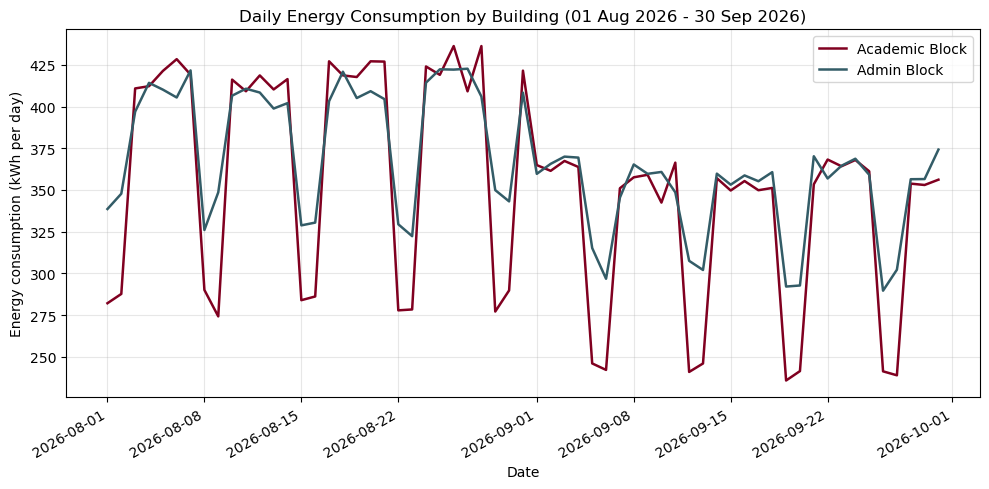

In [33]:
fig = ca.plot_line(costed); plt.show()

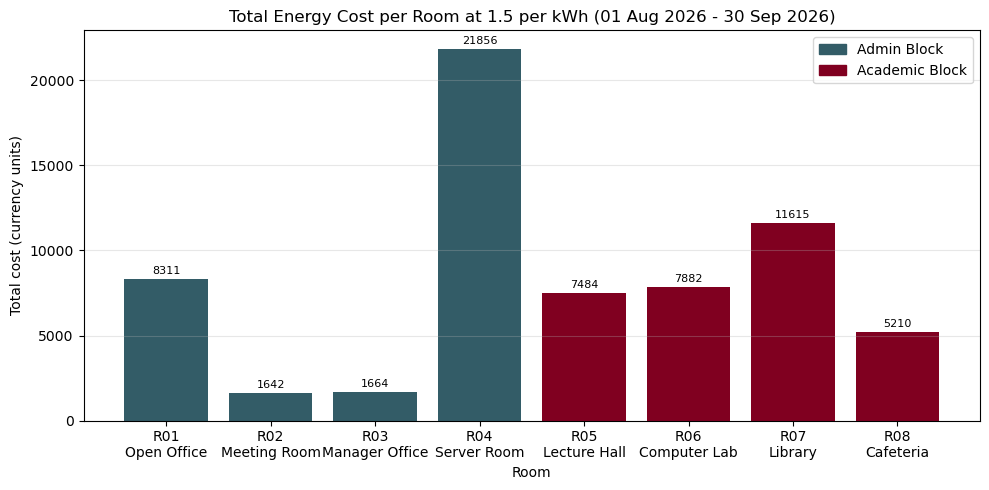

In [34]:
fig = ca.plot_bar(costed, PRICE); plt.show()

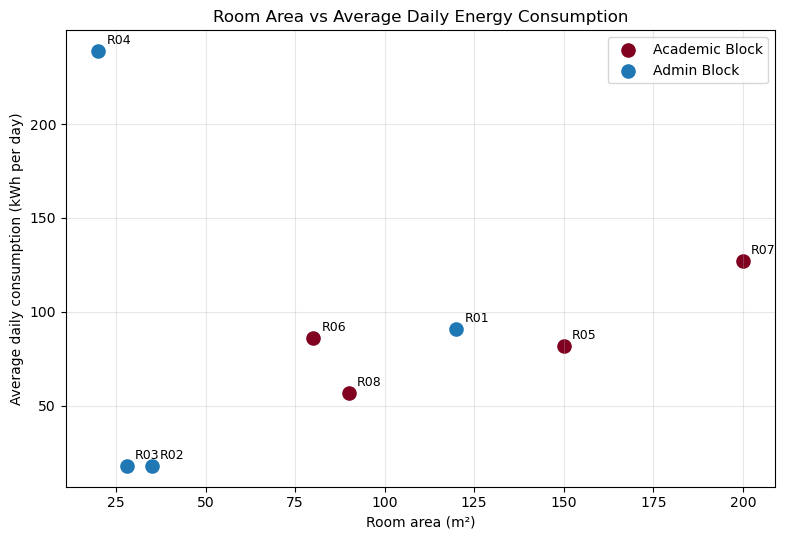

In [29]:
fig = ca.plot_scatter(costed); plt.show()

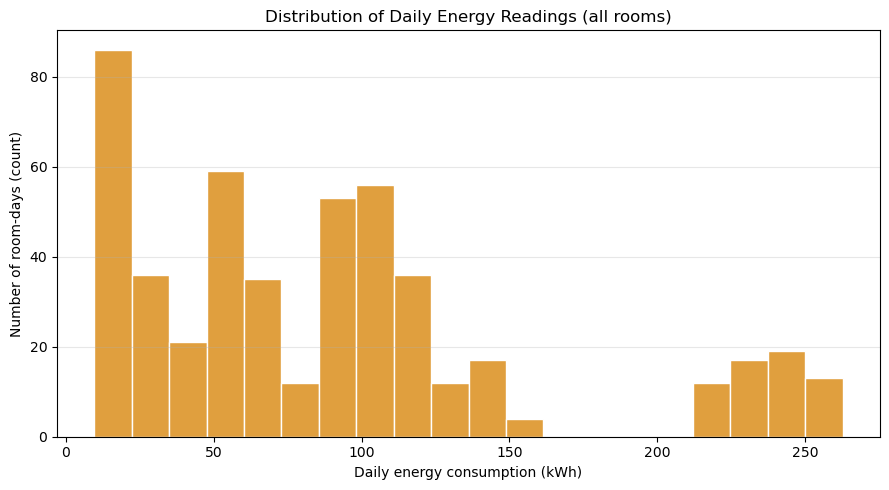

In [30]:
fig = ca.plot_histogram(costed); plt.show()

## 6. Findings
- **The server room (R04) is the biggest consumer** - about one third of all energy from only 20 m2 (the scatter chart shows it far above the other rooms) - because it runs 24 hours a day.
- **The two buildings use almost the same energy**: Admin Block slightly more than Academic Block, but without the server room it would use only about a third of Academic Block's energy.
- **Weekday vs weekend:** the open office, meeting room, manager office, lecture hall and computer lab use only about 55% of their weekday energy on weekends; the cafeteria uses about 70% and the library about 86%. The server room has no weekly pattern.
- **September is lower than August in every room** (between about 8% and 17% lower), and about 15% lower in total.
- **Actual use is only about 60-75% of the estimate** from installed power x hours, most likely because AC and equipment do not run at full power all day (the data cannot confirm this). The estimate is therefore an upper bound, and the AC saving shown above is an estimate too (an assumption of the model, not a measurement).
- **A 20% AC reduction** saves about 119 kWh per day (11% of the estimated total), with the largest daily savings in the Library (28 kWh), Server Room (24 kWh), Lecture Hall (19 kWh) and Open Office (18 kWh).
- **Data quality:** 2 duplicates were removed and 3 missing values were filled; the cleaning steps are listed in the cleaning report and `reports/filled_values.csv`.